In [1]:
import numpy
import matplotlib
import pandas

In [3]:
df = pandas.read_csv('exoplanet_data.csv', comment = "#")

In [6]:
df.shape # 597 rows, 92 columns

(597, 92)

In [7]:
print(df.columns)
# 'sy_vmag', 'sy_vmagerr1', 'sy_vmagerr2', 'sy_kmag','sy_kmagerr1'

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [8]:
# pl_name†;	Planet Name; Planet name most commonly used in the literature; literal meaning 
# hostname†; Host Name; Stellar name most commonly used in the literature; liertal meaning
# discoverymethod†; Discovery Method; Method by which the planet was first identified; which may have like transit, radial velocity, etc.
# st_spectype; Spectral Type; Classification of the star based on their spectral characteristics following the Morgan-Keenan system; OBAFGKM
# pl_eqt†; Equilibrium Temperature [K]; The equilibrium temperature of the planet as modeled by a black body heated only by its host star, 
# or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body;
# temperature of planet if no greenhouse effect
# pl_bmassj; Planet Mass*sin(i) [Jupiter Mass]; Minimum mass of a planet as measured by radial velocity, measured in units of masses of Jupiter;
# the radial velocity method can't get a perfect mass, so sine of inclination was left in as a parameter

In [11]:
df_s = df[['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']]

In [13]:
df_s.dropna()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
2,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
5,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
7,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
10,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000
...,...,...,...,...,...,...
572,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980000
576,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000000
581,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300000
586,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709000


In [14]:
df_s.shape # 75 rows, 6 columns

(597, 6)

In [15]:
print(df_s.head(5))
print(df_s.tail(5))
print(df_s.columns)

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
0   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.870000
1   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.912000
2  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
3  DMPP-1 b   DMPP-1  Radial Velocity         NaN     NaN   0.052859
4  DMPP-1 c   DMPP-1  Radial Velocity         NaN     NaN   0.034421
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
592    bet Pic c    bet Pic  Radial Velocity         NaN     NaN       9.00
593  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0       6.31
594  eps Ind A b  eps Ind A  Radial Velocity        K2 V     NaN       3.25
595  eps Ind A b  eps Ind A  Radial Velocity        K5 V     NaN       6.50
596  eps Ind A b  eps Ind A  Radial Velocity         NaN     NaN       7.63
Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')


In [18]:
df_s['discoverymethod'].value_counts()
# As follows

discoverymethod
Transit                      403
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64

Transit: Detects a planet when it passes in front of its host star, causing a slight, periodic dip in the star's apparent brightness.

Radial Velocity: Measures the periodic "wobble" of a star caused by the gravitational tug of an orbiting planet, which is revealed as Doppler shifts in the star's spectrum.

Microlensing: Detects a planet when the gravitational field of a foreground star and its planet briefly magnifies the light from a more distant background star.

Imaging: Directly captures the light from an exoplanet itself, which requires the planet to be bright and sufficiently far from its star to be resolved.

Transit Timing Variations: Identifies additional planets by observing tiny, non-periodic changes in the timing of a known planet's transits, caused by the gravitational pull of other bodies in the system.

Eclipse Timing Variations: Detects circumbinary planets by measuring small variations in the timing of eclipses in a binary star system, which are caused by the gravitational perturbation of an unseen third body.

Disk Kinematics: Finds young, forming planets by identifying localized "kinks" or deviations from the expected Keplerian motion of gas in a protoplanetary disk.

In [20]:
import matplotlib.pyplot as plt

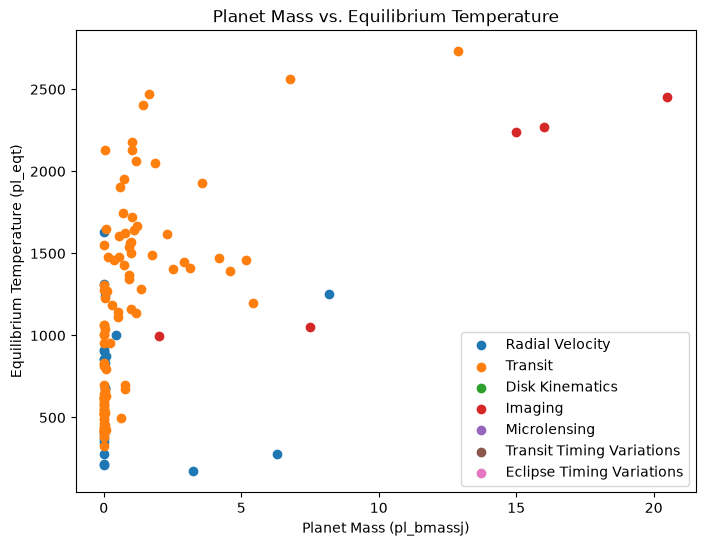

In [21]:
plt.figure(figsize=(8, 6))
for method in df_s['discoverymethod'].unique():
    subset = df_s[df_s['discoverymethod'] == method]
    plt.scatter(subset['pl_bmassj'], subset['pl_eqt'], label=method)
plt.title('Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Planet Mass (pl_bmassj)')
plt.ylabel('Equilibrium Temperature (pl_eqt)')
plt.legend()
plt.show()

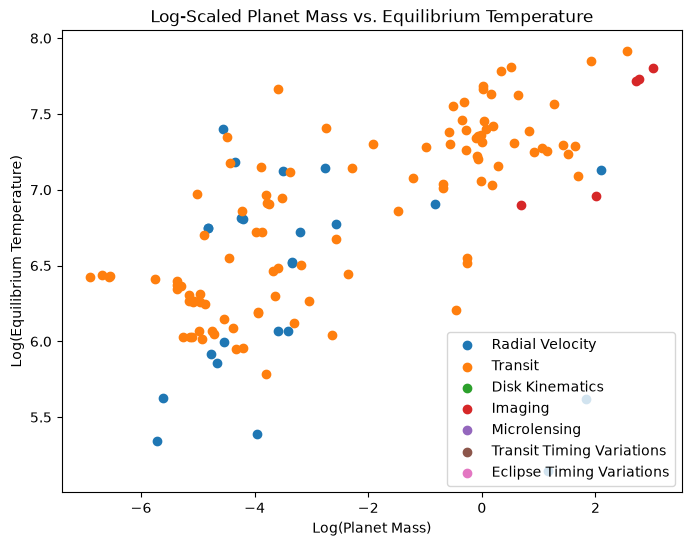

In [24]:
plt.figure(figsize=(8, 6))
for method in df_s['discoverymethod'].unique():
    subset = df_s[df_s['discoverymethod'] == method]
    plt.scatter(numpy.log(subset['pl_bmassj']), numpy.log(subset['pl_eqt']), label=method)
plt.title('Log-Scaled Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Log(Planet Mass)')
plt.ylabel('Log(Equilibrium Temperature)')
plt.legend()
plt.show()

In [25]:
# Exoplanets found by imaging method tend to be very massive compared to other planets

In [37]:
df_s.iloc[df_s[df_s['pl_bmassj']>5]['pl_eqt'].idxmin()]

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 593, dtype: object

In [38]:
# eps Ind A b, index 593, equilibrium temperature 275K, 6.31 Jupiter mass, orbiting K-type star which is slightly less massive than sun

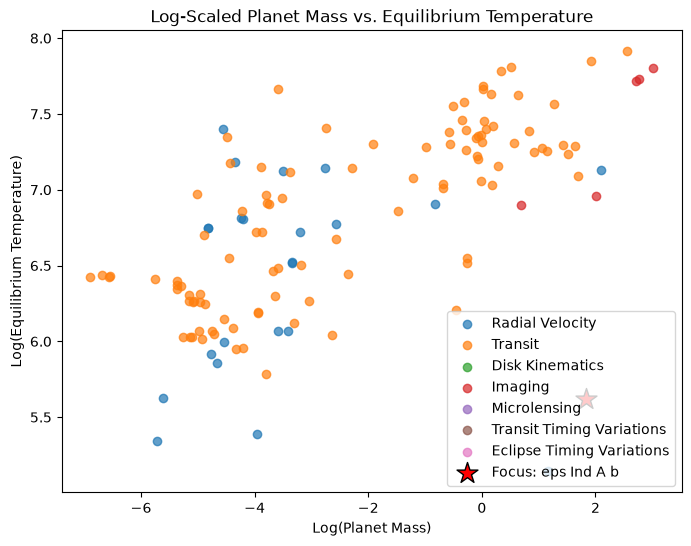

In [40]:
plt.figure(figsize=(8, 6))
for method in df_s['discoverymethod'].unique():
    subset = df_s[df_s['discoverymethod'] == method]
    plt.scatter(numpy.log(subset['pl_bmassj']), numpy.log(subset['pl_eqt']), label=method, alpha=0.7)
focus_row = df_s.loc[593]
focus_x = numpy.log(focus_row['pl_bmassj'])
focus_y = numpy.log(focus_row['pl_eqt'])
focus_name = focus_row['pl_name']
plt.scatter(
    focus_x, 
    focus_y, 
    color='red',
    marker='*',
    s=250,
    edgecolor='black',
    label=f"Focus: {focus_name}",
    zorder=5
)
plt.title('Log-Scaled Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Log(Planet Mass)')
plt.ylabel('Log(Equilibrium Temperature)')
plt.legend()
plt.show()

In [ ]:
# "A temperate super-Jupiter imaged with JWST in the mid-infrared"
# A giant planet different from previous claims were found at a temperate temperature, with high metallicity, C-O ratio and opaque atmosphere.
# Yes
# Significient cooler while being massive compared to other planets detected
# Yes, they match